In [1]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


sys.path.append(os.path.join(os.getcwd(), '../import'))

from utils import read_utils
from utils import plot_utils

In [2]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

In [3]:
n = 3

modes_manifold = list()
recon_manifold = list()
vars_expl = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=n)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)

	modes_manifold.append(pd.DataFrame(data=trace_reduced, columns=[f'PC{i+1}' for i in range(n)]))
	recon_manifold.append(pd.DataFrame(data=trace_reconstructed, columns=trace.columns))

	vars_expl.append(sum(pca.explained_variance_ratio_))

0.5681135652216489


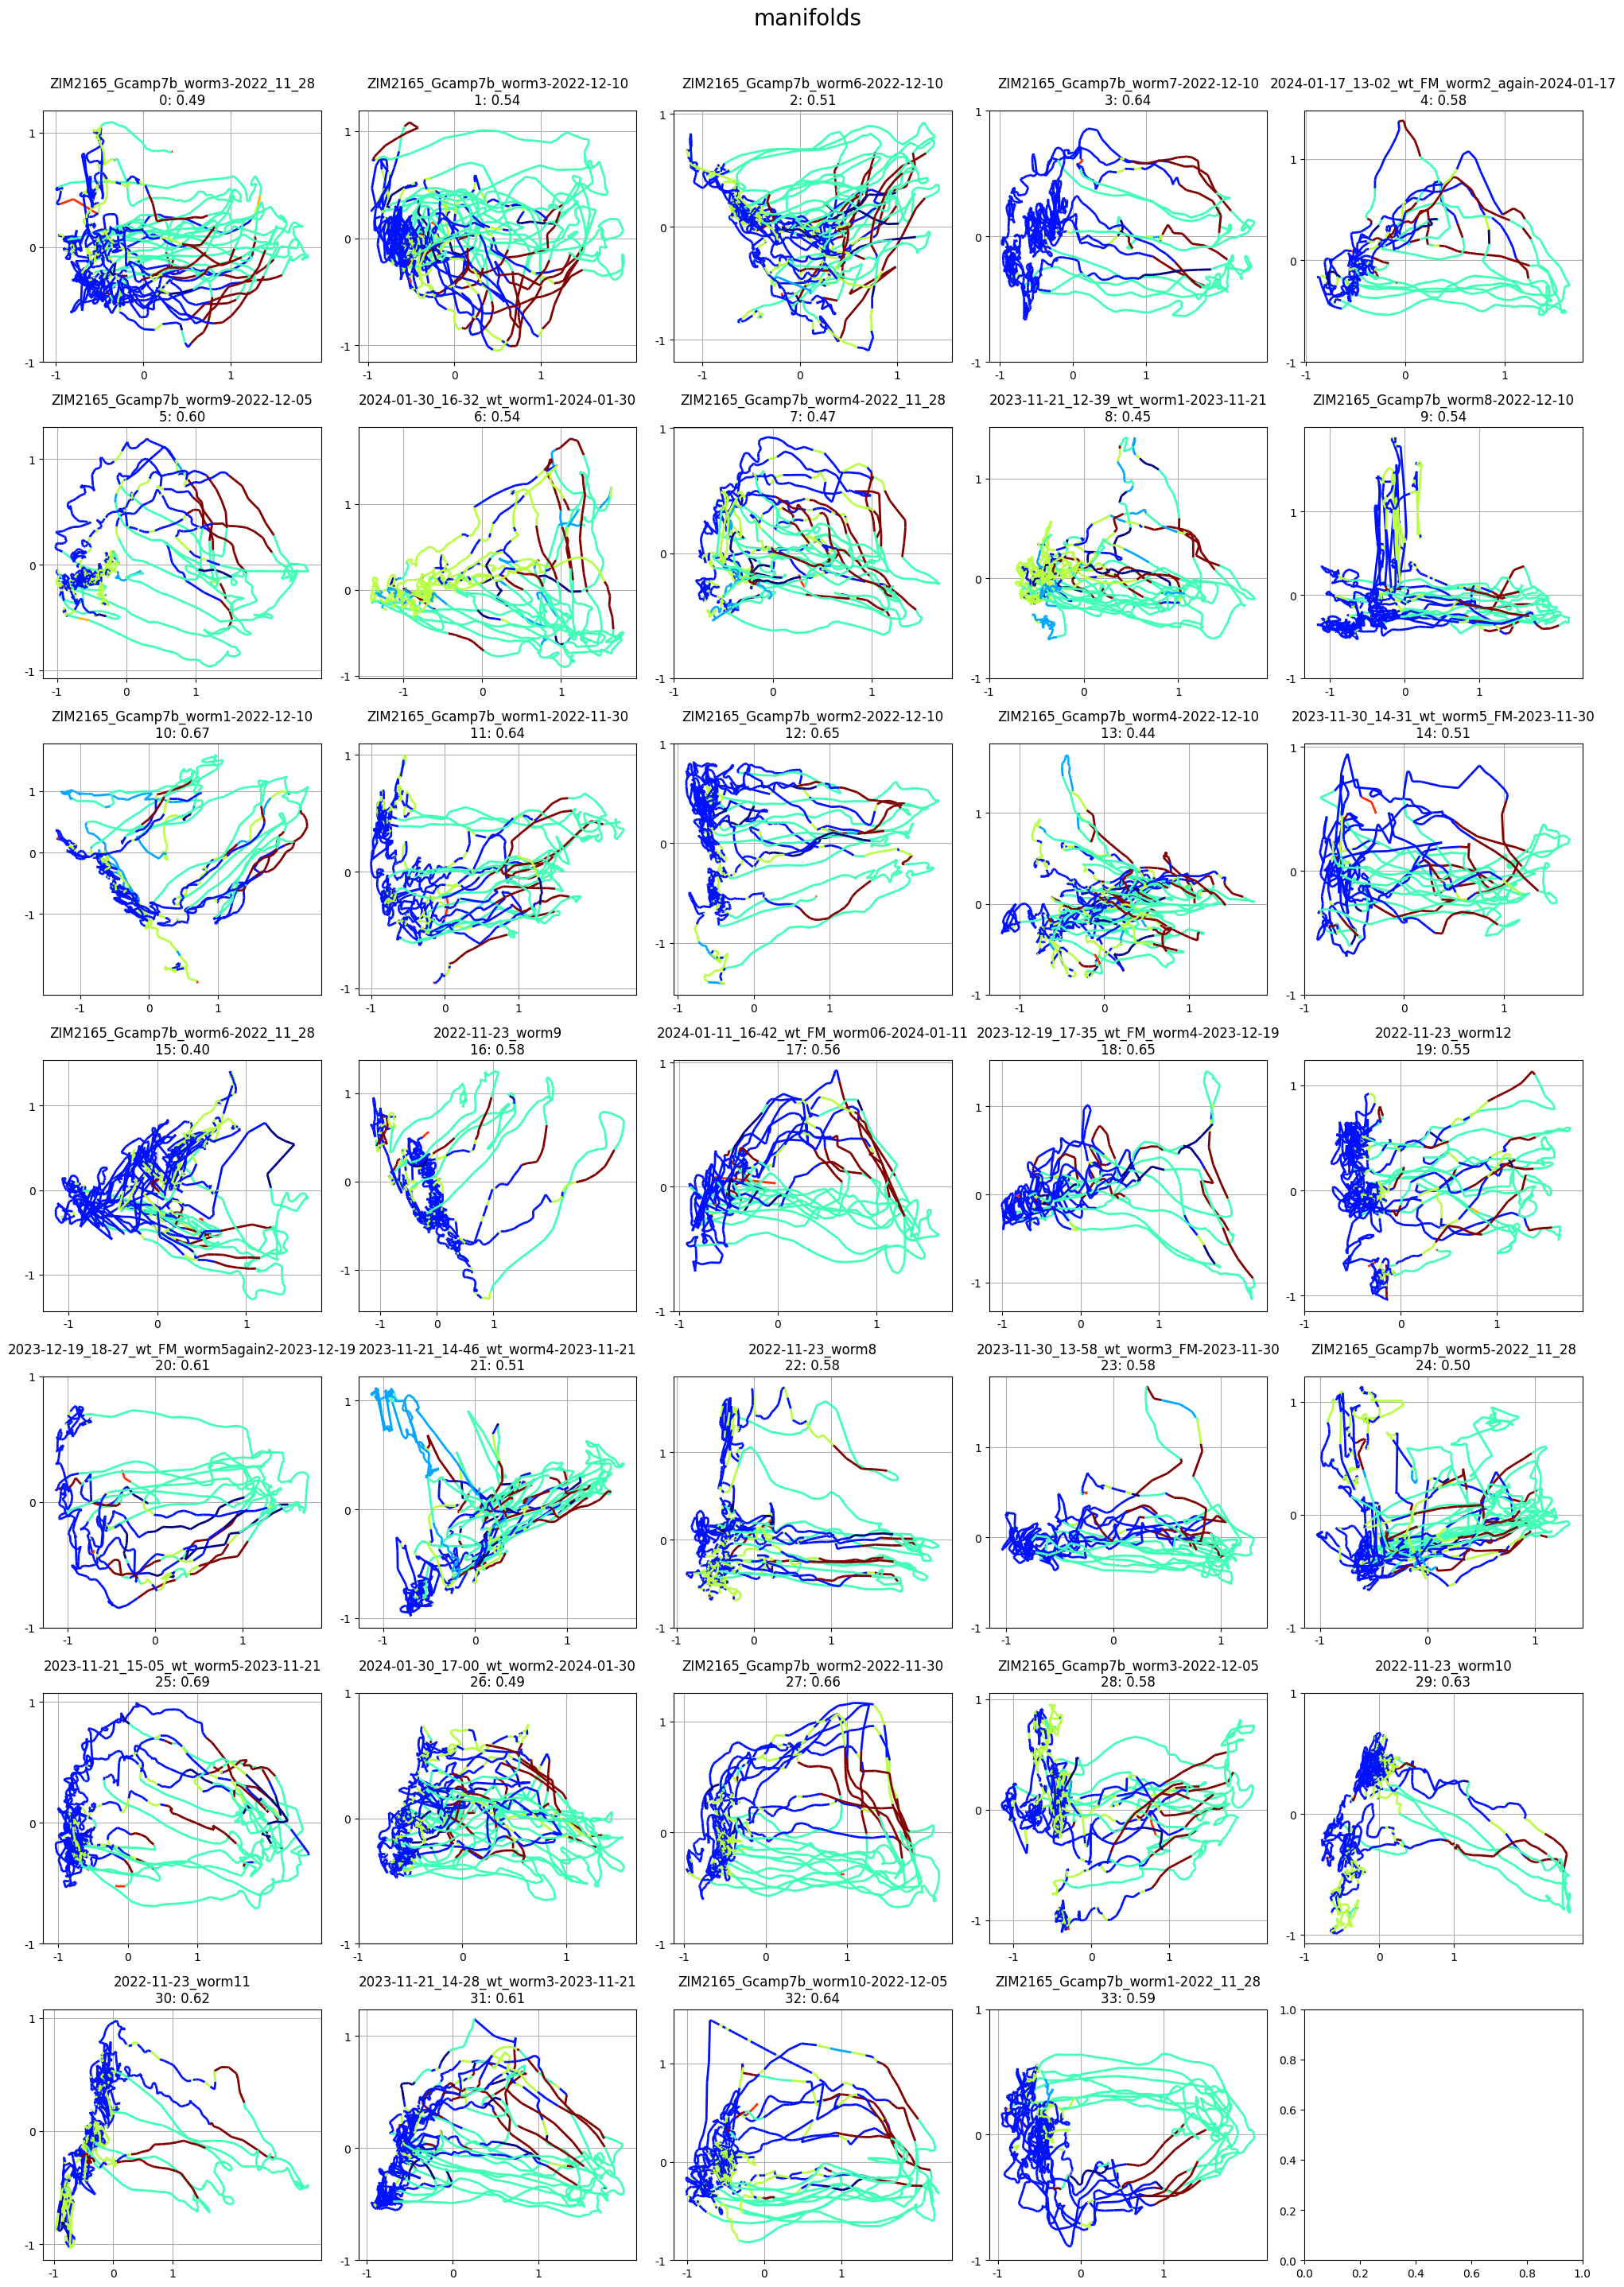

In [4]:
plot_utils.plot_manifolds(filenames, modes_manifold, discrete_states, vars_expl)

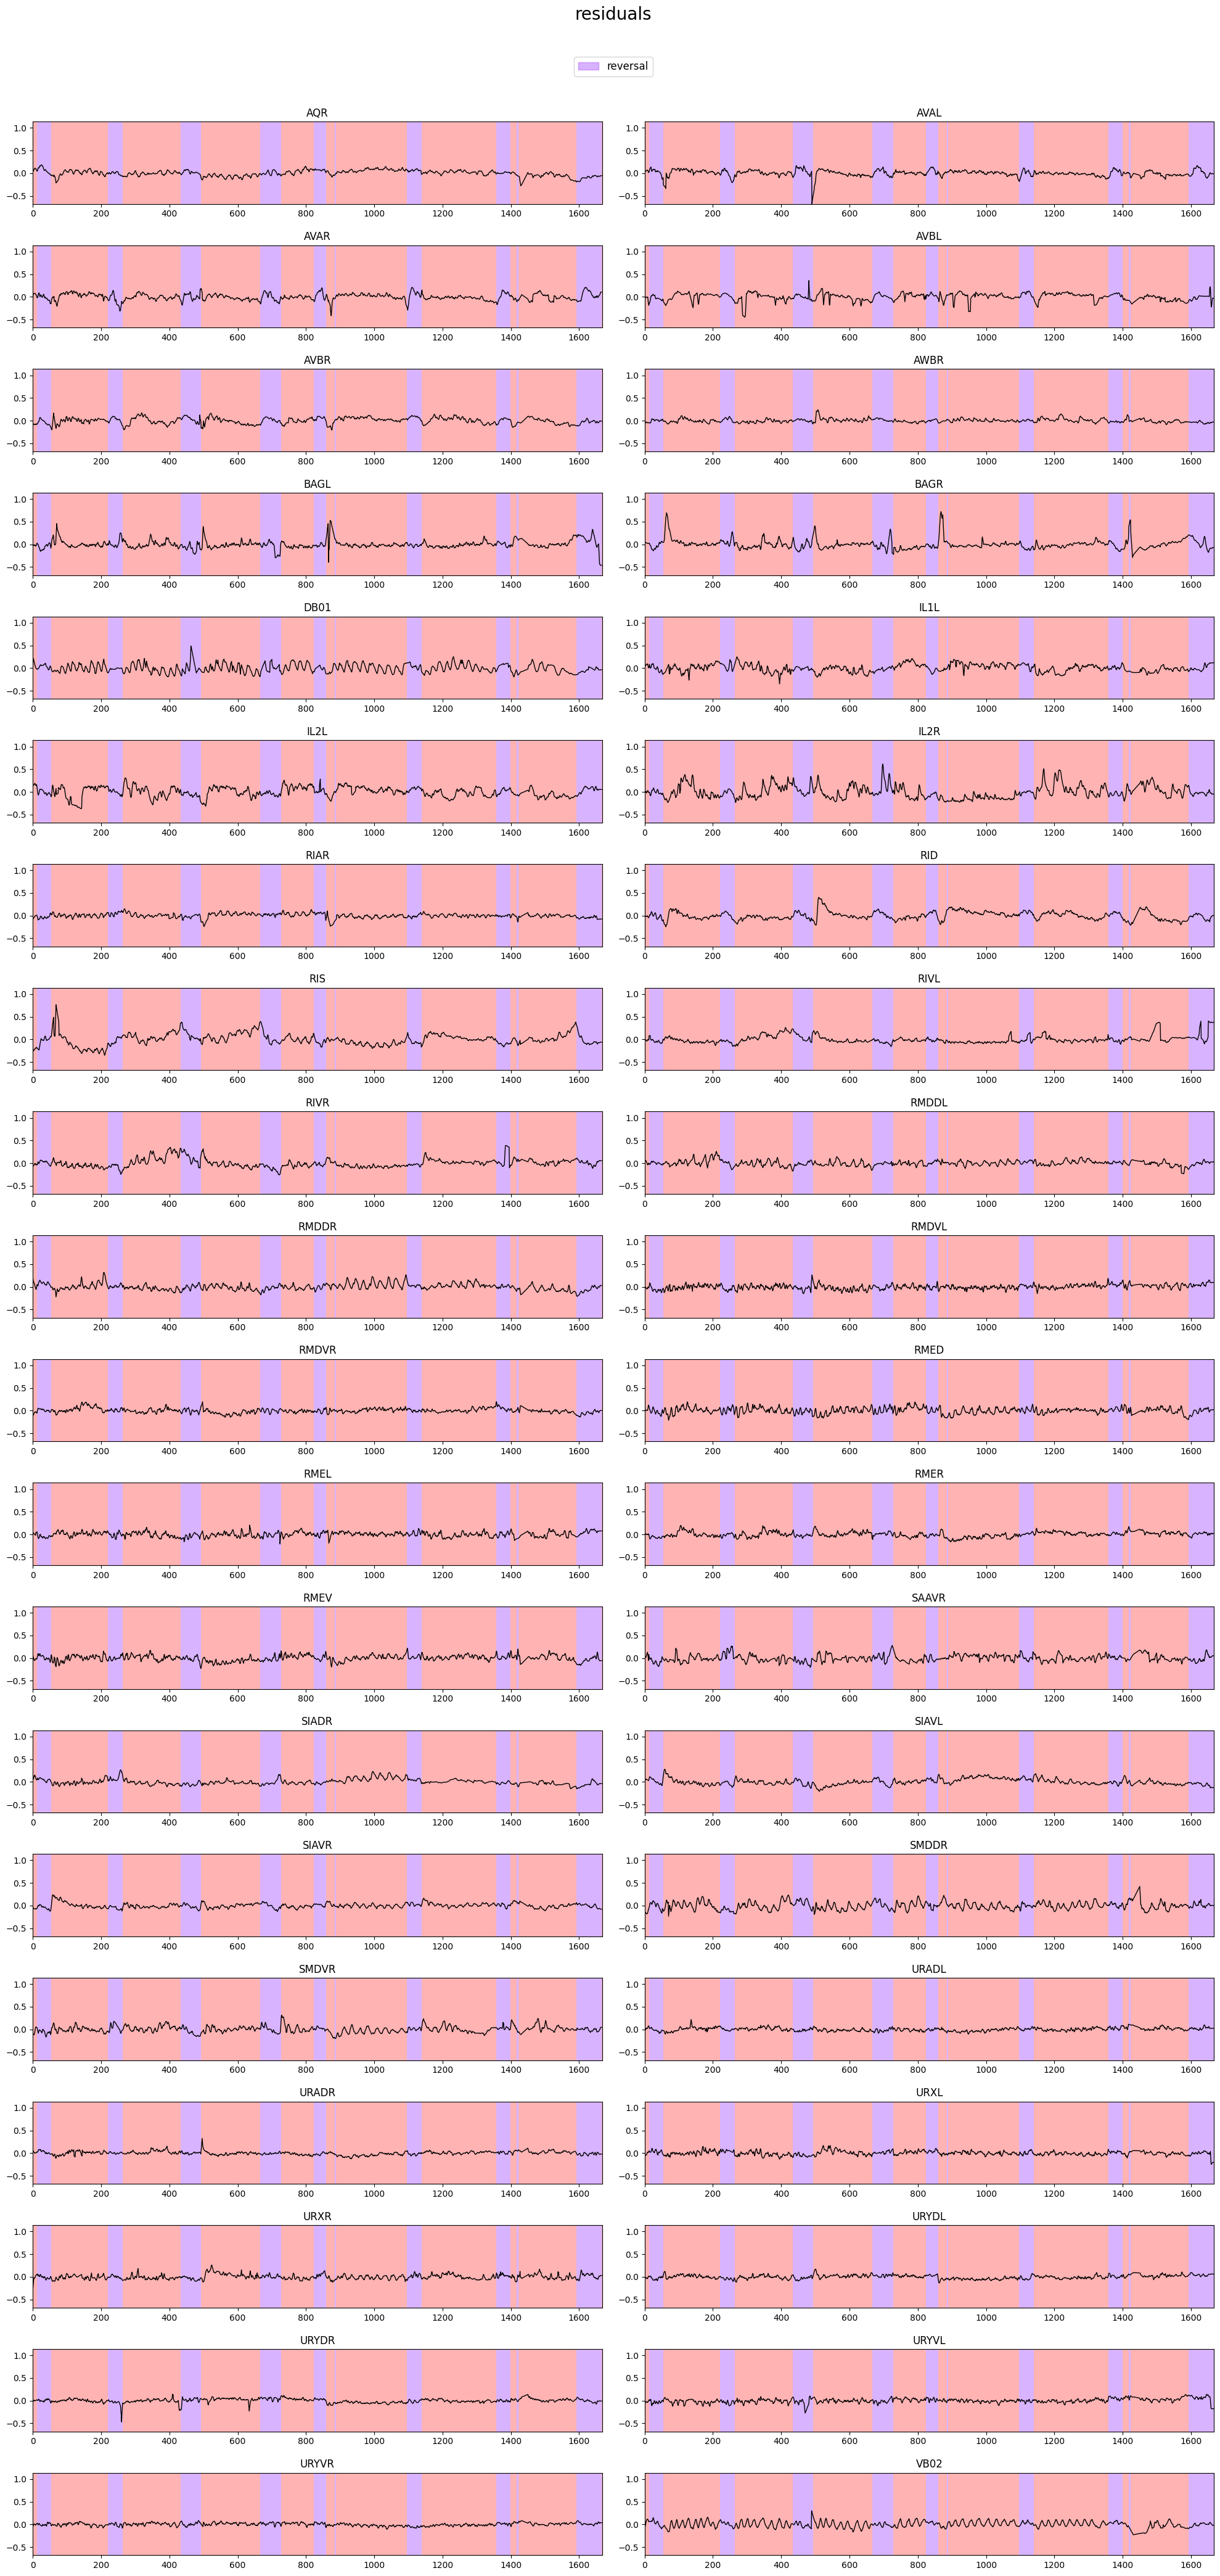

In [7]:
traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recon_manifold)]

worm_id = 33
plot_utils.plot_traces('residuals', [traces_residual[worm_id]], discrete_states[worm_id]['REV'], n_plots=None, n_columns=2, ylimits=None)